In [15]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
# Setup cell
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from einops import rearrange
from xlstm import xLSTMBlockStack, xLSTMBlockStackConfig
from xlstm.blocks.slstm.block import sLSTMBlockConfig
from xlstm.blocks.slstm.layer import sLSTMLayerConfig
from xlstm.components.feedforward import FeedForwardConfig

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

# 1. Data Reading and Pre-processing

In [17]:
# Pre-processing Cell
# Reads data and processes it in exact same way as in arima.ipynb
# Read Weather dataset
df = pd.read_csv('/content/drive/MyDrive/mpi_roof_2025.csv', encoding = "unicode_escape")

# Selecting only 'Date Time' and 'T(degC)'
df = df[['Date Time', 'T (degC)']]

# Dropping potential NA values
df = df.dropna()

# Converting to proper date time format
df["Date Time"] = pd.to_datetime(df["Date Time"], format = "mixed")
df = df.set_index("Date Time").asfreq("10min")

# Select rows for short-term forecasting
# Total of 72 hours
df_short = df["2025-01-01":"2025-01-05"]

# Select rows for long-term forecasting
# Total of 5 months
df_long = df["2025-01-01":"2025-05-31"]

# 2. pLSTM Architecture

In [18]:
# Configs for pLSTM
class Configs:
    seq_len            = 24    # use last 24 hours (matches short-term LSTM)
    pred_len           = 24    # forecast next 24 hours
    channel            = 1     # univariate (just T degC)
    embedding_dim      = 64    # matches hidden_size in your LSTM
    patch_size         = 4     # each patch covers 4 timesteps
    stride             = 2     # patches overlap by 2
    num_heads          = 4     # attention heads
    conv1d_kernel_size = 4     # conv kernel
    num_blocks         = 2     # number of xLSTM blocks

configs = Configs()

In [19]:
from xlstm import xLSTMBlockStack, xLSTMBlockStackConfig
from xlstm.blocks.mlstm.block import mLSTMBlockConfig
from xlstm.blocks.mlstm.layer import mLSTMLayerConfig

# pLSTM Architecture
class Model(nn.Module):
    def __init__(self, configs):
        super(Model, self).__init__()
        self.seq_len       = configs.seq_len
        self.pred_len      = configs.pred_len
        self.channel       = configs.channel
        self.embedding_dim = configs.embedding_dim
        self.patch_size    = configs.patch_size
        self.stride        = configs.stride
        self.patch_num     = (configs.seq_len - self.patch_size) // self.stride + 1

        cfg = xLSTMBlockStackConfig(
            mlstm_block=mLSTMBlockConfig(
                mlstm=mLSTMLayerConfig(
                    conv1d_kernel_size=configs.conv1d_kernel_size,
                    qkv_proj_blocksize=4,
                    num_heads=configs.num_heads
                )
            ),
            context_length=self.patch_num,
            num_blocks=configs.num_blocks,
            embedding_dim=configs.embedding_dim,
            slstm_at=[],   # no sLSTM blocks — avoids the CUDA kernel issue
        )

        self.embedding   = nn.Linear(self.patch_size, self.embedding_dim)
        self.xlstm_stack = xLSTMBlockStack(cfg)
        self.projection  = nn.Linear(self.embedding_dim * self.patch_num, self.pred_len)

    def forward(self, x):
        B, L, C = x.shape
        x = rearrange(x, 'b l c -> b c l')
        x = rearrange(x, 'b c l -> (b c) l')
        x = x.unfold(dimension=-1, size=self.patch_size, step=self.stride)
        x = self.embedding(x)
        x = self.xlstm_stack(x)
        x = x.flatten(1)
        x = self.projection(x)
        x = rearrange(x, '(b c) l -> b c l', b=B, c=C)
        x = rearrange(x, 'b c l -> b l c')
        return x

# 3. Short-term Forecasting

In [20]:
# Train/test split
# Training: 48 hours
# Testing: 24 hours
train = df_short["2025-01-01":"2025-01-04 23:50:00"]
test  = df_short["2025-01-05":"2025-01-05 23:50:00"]

# Resample into 1h intervals
train_hourly = train.resample("1h").mean()
test_hourly  = test.resample("1h").mean()

train_vals = train_hourly["T (degC)"].values.reshape(-1, 1)
test_vals  = test_hourly["T (degC)"].values.reshape(-1, 1)

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_vals)
test_scaled  = scaler.transform(test_vals)

# Create sequences
def create_sequences(data, seq_len):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i : i + seq_len])
        y.append(data[i + seq_len])
    # X: [B, seq_len, 1], y: [B, 1, 1]
    return (torch.tensor(np.array(X), dtype=torch.float32),
            torch.tensor(np.array(y), dtype=torch.float32))

SEQ_LEN = configs.seq_len

X_train, y_train = create_sequences(train_scaled, SEQ_LEN)
X_test,  y_test  = create_sequences(
    np.concatenate([train_scaled[-SEQ_LEN:], test_scaled]), SEQ_LEN
)

print(f"X_train: {X_train.shape}")  # (B, 24, 1)
print(f"X_test:  {X_test.shape}")   # (24, 24, 1)

X_train: torch.Size([72, 24, 1])
X_test:  torch.Size([24, 24, 1])


In [22]:
# Training cell
device    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model     = Model(configs).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS     = 50
BATCH_SIZE = 16

dataset    = torch.utils.data.TensorDataset(X_train, y_train)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()

        # pLSTM predicts full pred_len; we only need next step for sequence prediction
        out  = model(X_batch)           # [B, pred_len, 1]
        loss = criterion(out[:, 0, :], y_batch.squeeze(1))
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dataloader)
    train_losses.append(avg_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.6f}")

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([16])) that is different to the input size (torch.Size([16, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([8])) that is different to the input size (torch.Size([8, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Epoch 10/50 | Loss: 0.088274
Epoch 20/50 | Loss: 0.074896
Epoch 30/50 | Loss: 0.116662
Epoch 40/50 | Loss: 0.064965
Epoch 50/50 | Loss: 0.072333


In [24]:
# Forecasting cell
model.eval()
preds_scaled = []

with torch.no_grad():
    for i in range(len(X_test)):
        out = model(X_test[i].unsqueeze(0).to(device))  # [1, pred_len, 1]
        preds_scaled.append(out[0, 0, 0].cpu().item())  # take first predicted step

preds_scaled = np.array(preds_scaled).reshape(-1, 1)
preds  = scaler.inverse_transform(preds_scaled)
actual = scaler.inverse_transform(y_test.squeeze().numpy().reshape(-1, 1))

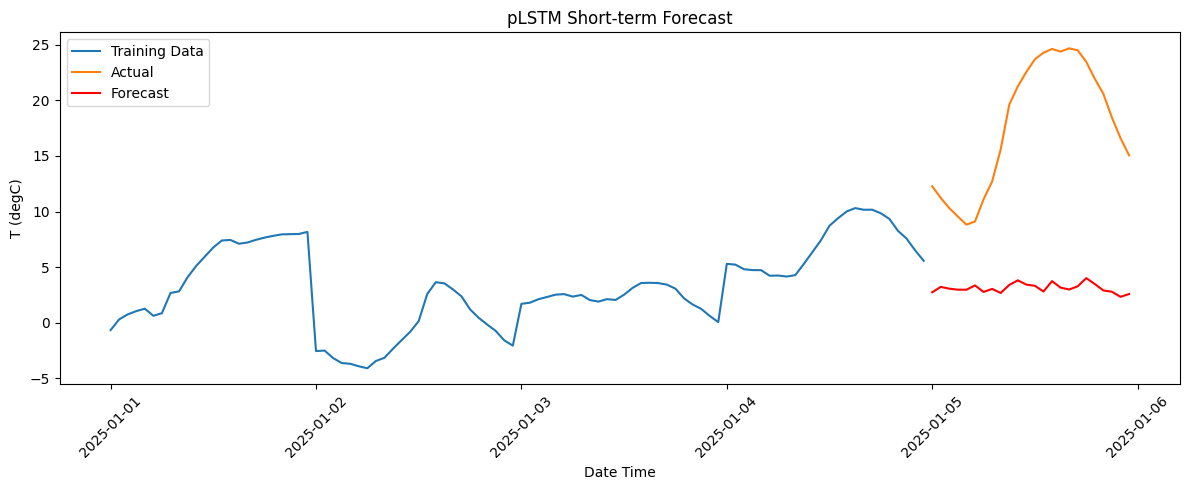

In [ ]:
# Forecasting plot
plt.figure(figsize=(12, 5))
plt.plot(train_hourly.index, train_hourly["T (degC)"], label="Training Data")
plt.plot(test_hourly.index,  test_hourly["T (degC)"],  label="Actual")
plt.plot(test_hourly.index,  preds,                    label="Forecast", color="red")
plt.title("pLSTM Short-term Forecast")
plt.xlabel("Date Time")
plt.ylabel("T (degC)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
# Evaluation
mae  = mean_absolute_error(actual, preds)
rmse = np.sqrt(mean_squared_error(actual, preds))
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

MAE:  14.650
RMSE: 15.683


In [ ]:
plstm_results = pd.DataFrame({
    "actual":   test_hourly["T (degC)"].values,
    "forecast": preds.flatten()
}, index=test_hourly.index)

plstm_results.to_csv("/content/drive/MyDrive/plstm_results.csv")